In [1]:
# This import is necessary to run the code cell-by-cell
from lab05_solution import *

In [2]:
op = Lab05_op()
kdata, sens_maps, noise_maps = op.load_data()

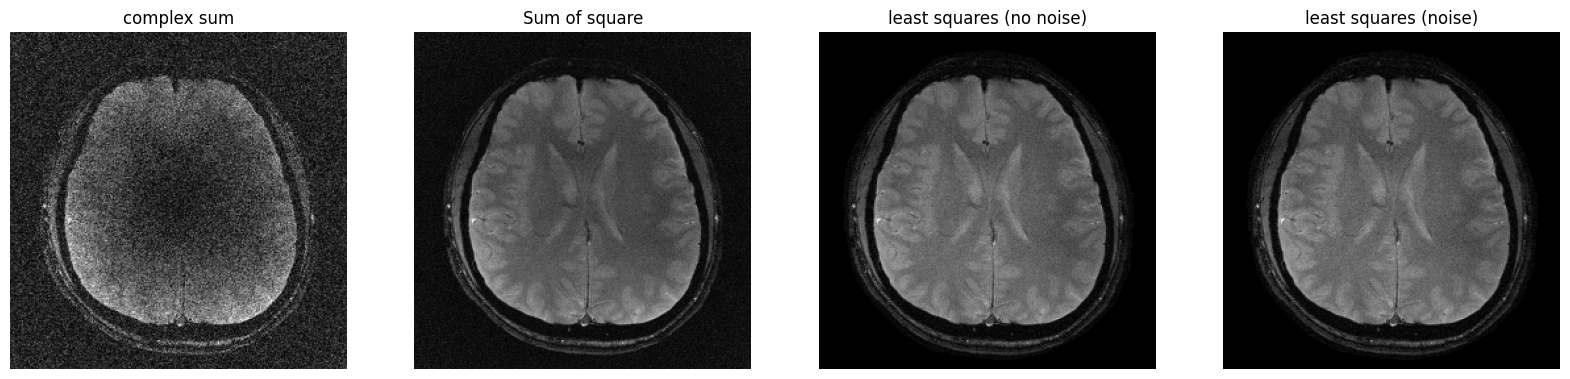

In [3]:
# coil images with coil sensitivity maps
coil_imgs = utils.ifft2c(kdata, axes=(0, 1))

compx_recon = utils.cmplx_sum(coil_imgs)
sos_recon = op.sos_comb(coil_imgs)
ls_wo = op.ls_comb(coil_imgs, sens_maps)

PSI = op.get_psi(noise_maps)
ls_w = op.ls_comb(coil_imgs, sens_maps, PSI)
utils.imshow([compx_recon, sos_recon, ls_wo, ls_w], titles=["complex sum", "Sum of square", "least squares (no noise)", "least squares (noise)"])

In [ ]:
senses = []
gs = []
title_R, title_g = [], []
for R in [2, 3, 4]:
    unaliased_img, g_maps = op.sense_recon(aliased_img, sens_maps, PSI, R)
    senses.append(unaliased_img)
    gs.append(g_maps)
    title_R.append(f"R={R}")
    title_g.append(f"g-factor={np.mean(g_maps[np.nonzero(g_maps)]): .2f}")
    

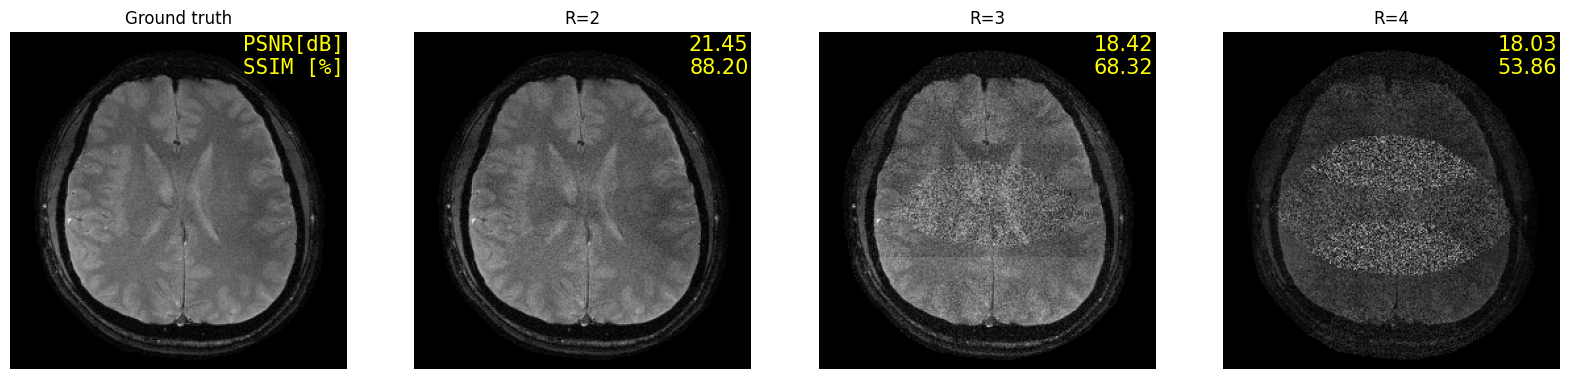

In [5]:
utils.imshow(senses, gt=ls_w, titles=title_R)

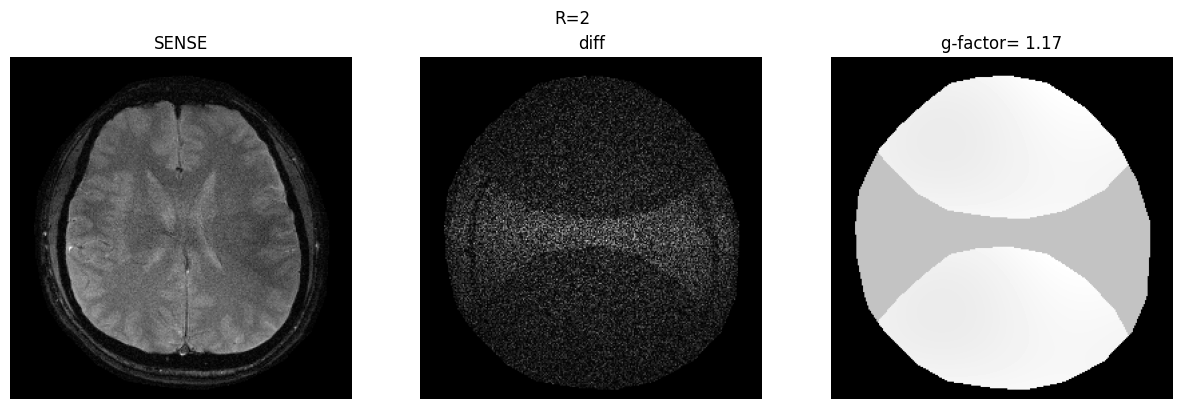

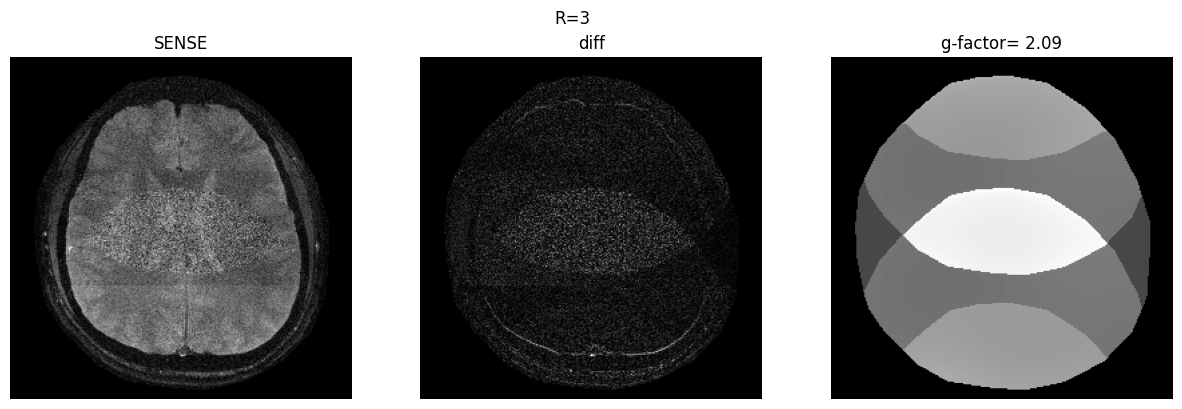

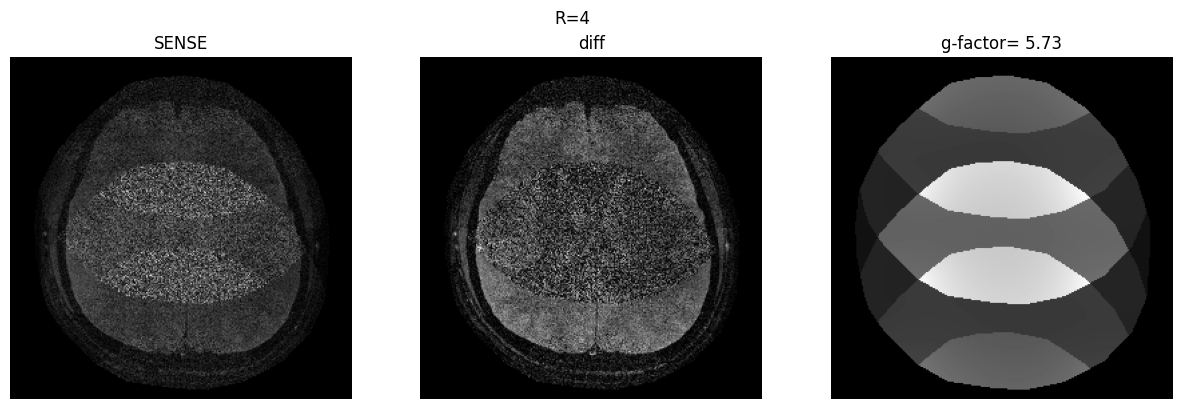

In [6]:
senses_norm = [utils.normalization(i) for i in senses]
ls_wPSI_norm = utils.normalization(ls_w)
senses_diff = [ls_wPSI_norm - i for i in senses_norm]

for i in range(len(senses_norm)):
    utils.imshow(
        [senses_norm[i], senses_diff[i], gs[i]],
        titles=["SENSE", "diff", title_g[i]],
        suptitle=title_R[i],
    )